In [ ]:
# Cell 1: load the data and build the patient-grouped train / validation / test split
import numpy as np
import pandas as pd
import random
import time
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold

# fix the random seed so results can be repeated
SEED=42
np.random.seed(SEED)
random.seed(SEED)

# CHANGE THIS to the folder that contains metadata.csv and the images folder
BASE=Path(r"C:\Users\LAPTOP\Desktop\Multi-Modal Data Analysis\Group Project\Final\zr7vgbcyr2-1")
# folder where figures, tables and saved features are stored
OUT=BASE.parent/"final_outputs"
OUT.mkdir(exist_ok=True)

# load the metadata table
df=pd.read_csv(BASE/"metadata.csv")
print("metadata shape:",df.shape)

# find every image file 
image_paths={}
for p in (BASE/"images").rglob("*"):
    if p.suffix.lower() in [".png",".jpg",".jpeg"]:
        image_paths[p.name]=p
print("images found:",len(image_paths))
print("metadata rows with an image:",df["img_id"].isin(image_paths.keys()).sum())

# turn the diagnosis text into a number 0-5
classes=["ACK","BCC","MEL","NEV","SCC","SEK"]
label_map={}
for i,c in enumerate(classes):
    label_map[c]=i
df["label"]=df["diagnostic"].map(label_map)

# split 1: hold out about 1/7 of patients for the test set
split1=StratifiedGroupKFold(n_splits=7,shuffle=True,random_state=SEED)
trval_idx,test_idx=next(split1.split(df,y=df["diagnostic"],groups=df["patient_id"]))
trval_df=df.iloc[trval_idx]
test_df=df.iloc[test_idx]

# split 2: take 1/6 of the rest as the validation set
split2=StratifiedGroupKFold(n_splits=6,shuffle=True,random_state=SEED)
tr_idx, va_idx=next(split2.split(trval_df,y=trval_df["diagnostic"],groups=trval_df["patient_id"]))
train_df=trval_df.iloc[tr_idx]
val_df=trval_df.iloc[va_idx]

# record which split each row belongs to
df["split"]="unassigned"
df.loc[train_df.index,"split"]="train"
df.loc[val_df.index,"split"]="validation"
df.loc[test_df.index,"split"]="test"

# how many images ended up in each split
print(df["split"].value_counts())
print(pd.crosstab(df["split"],df["diagnostic"]))

# check that no patient appears in two splits
train_patients=set(train_df.patient_id)
val_patients=set(val_df.patient_id)
test_patients=set(test_df.patient_id)
print("patient overlap train/val, train/test, val/test:",len(train_patients & val_patients),len(train_patients & test_patients),len(val_patients & test_patients))

# save the table with the split column
df.to_csv(OUT/"metadata_with_patient_split.csv",index=False)
print("saved to:",OUT)

metadata shape: (2298, 26)
images found: 2298
metadata rows with an image: 2298
split
train         1632
test           358
validation     308
Name: count, dtype: int64
diagnostic  ACK  BCC  MEL  NEV  SCC  SEK
split                                   
test        100  144    7   39   35   33
train       530  584   36  167  141  174
validation  100  117    9   38   16   28
patient overlap train/val, train/test, val/test: 0 0 0
saved to: C:\Users\LAPTOP\Desktop\Multi-Modal Data Analysis\Group Project\Final\final_outputs


diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64
diagnostic
BCC    36.77
ACK    31.77
NEV    10.62
SEK    10.23
SCC     8.36
MEL     2.26
Name: proportion, dtype: float64
                     missing    pct
background_mother        822  35.77
background_father        818  35.60
smoke                    804  34.99
drink                    804  34.99
pesticide                804  34.99
gender                   804  34.99
skin_cancer_history      804  34.99
cancer_history           804  34.99
has_piped_water          804  34.99
has_sewage_system        804  34.99
fitspatrick              804  34.99
diameter_1               804  34.99
diameter_2               804  34.99
rows with ALL clinical fields missing: 804

% of each diagnosis with no clinical fields:
col_0       False  True 
diagnostic              
ACK          38.8   61.2
BCC         100.0    0.0
MEL         100.0    0.0
NEV          30.7   69.3
SCC         100.0    0.0
SEK    

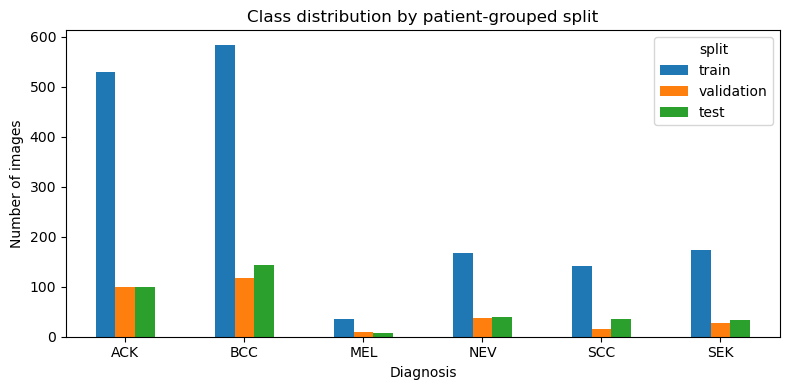

In [ ]:
# Cell 2: look at the data (class balance, missing values, odd values, image sizes)

#  class balance
print(df["diagnostic"].value_counts())
print((df["diagnostic"].value_counts(normalize=True)*100).round(2))

#  missing values
miss=pd.DataFrame({"missing":df.isna().sum(),"pct":(df.isna().mean()*100).round(2)})
print(miss[miss["missing"]>0].sort_values("pct",ascending=False))

#  is the missingness random? compare with diagnosis and biopsy status
# the clinical fields that tend to be missing together
clinical_cols=["smoke","drink","pesticide","gender","skin_cancer_history","cancer_history","has_piped_water","has_sewage_system","fitspatrick","diameter_1","diameter_2"]
no_clin=df[clinical_cols].isna().all(axis=1)
print("rows with ALL clinical fields missing:",no_clin.sum())
print("\n% of each diagnosis with no clinical fields:")
print((pd.crosstab(df["diagnostic"],no_clin,normalize="index")*100).round(1))
print("\nmissing vs biopsed:")
print(pd.crosstab(df["biopsed"],no_clin))

#  suspicious values
print("\nage range:",df["age"].min(),"-",df["age"].max())
print("diameter = 0 rows:",((df["diameter_1"]==0) | (df["diameter_2"]==0)).sum())
print("diameter > 50 rows:",((df["diameter_1"]>50) | (df["diameter_2"]>50)).sum())
print("itch values:",df["itch"].value_counts(dropna=False).to_dict())

#  repeated images per patient/lesion (why we split by patient)
print("\npatients with >1 image:",(df.groupby("patient_id")["img_id"].nunique()>1).sum())
print("lesions with >1 image:",(df.groupby("lesion_id")["img_id"].nunique()>1).sum())

# image sizes and colour modes
sizes=[]
for name in df["img_id"]:
    with Image.open(image_paths[name]) as im:
        sizes.append((im.width,im.height,im.mode))
size_df=pd.DataFrame(sizes,columns=["w","h","mode"])
print("\n",size_df[["w","h"]].describe().round(0))
print(size_df["mode"].value_counts())

# # bar chart of images per diagnosis in each split
counts=pd.crosstab(df["diagnostic"],df["split"])[["train","validation","test"]]
ax=counts.plot(kind="bar",figsize=(8,4))
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Number of images")
ax.set_title("Class distribution by patient-grouped split")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT/"fig_class_by_split.png",dpi=200)
plt.show()

In [ ]:
# Cell 3: prepare the patient (metadata) features and train metadata-only models
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import f1_score,balanced_accuracy_score,accuracy_score,roc_auc_score
from xgboost import XGBClassifier

# zero diameters are impossible, so treat them as missing
df.loc[df["diameter_1"]<=0,"diameter_1"]=np.nan
df.loc[df["diameter_2"]<=0,"diameter_2"]=np.nan

# conservative=the 6 proposal features
# full=also adds the fields that are ~35% missing in a systematic way
cons_cat=["region","itch","hurt","bleed","elevation"]
cons_num=["age"]
full_cat=cons_cat+["grew","changed","gender","smoke","drink","pesticide","skin_cancer_history","cancer_history"]
full_num=["age","fitspatrick","diameter_1","diameter_2"]

# make categoricals text so NaN/UNK become their own category
for col in full_cat:
    df[col]=df[col].astype(str)

# rebuild the three splits from the cleaned table
train_df=df[df["split"]=="train"].reset_index(drop=True)
val_df=df[df["split"]=="validation"].reset_index(drop=True)
test_df=df[df["split"]=="test"].reset_index(drop=True)
# labels (0-5) for each split
y_train=train_df["label"].values
y_val=val_df["label"].values
y_test=test_df["label"].values

# preprocessing is always fitted on the train rows only
def make_prep(cat_cols,num_cols):
    num_pipe=Pipeline([("imp",SimpleImputer(strategy="median",add_indicator=True)),("sc",StandardScaler())])
    cat_pipe=OneHotEncoder(handle_unknown="ignore",sparse_output=False)
    return ColumnTransformer([("num",num_pipe,num_cols),("cat",cat_pipe,cat_cols)])

# conservative metadata: fit on train, then apply to validation and test
prep_cons=make_prep(cons_cat,cons_num)
Mc_train=prep_cons.fit_transform(train_df)
Mc_val=prep_cons.transform(val_df)
Mc_test=prep_cons.transform(test_df)

# full metadata 
prep_full=make_prep(full_cat,full_num)
Mf_train=prep_full.fit_transform(train_df)
Mf_val=prep_full.transform(val_df)
Mf_test=prep_full.transform(test_df)
print("conservative features:",Mc_train.shape[1]," full features:",Mf_train.shape[1])

# evaluation: one row of metrics per model and split (test is not touched here)
cancer=[1,2,4]   # BCC, MEL, SCC
results=[]
probs={}          

# scores one model: accuracy, balanced accuracy, macro-F1, AUC, cancer sensitivity, melanoma recall
def evaluate(name,split,y_true, prob):
    pred=prob.argmax(1)
    is_cancer=np.isin(y_true,cancer)
    pred_cancer=np.isin(pred,cancer)
    results.append({
        "model":name,"split":split,
        "acc":accuracy_score(y_true,pred),
        "bal_acc":balanced_accuracy_score(y_true,pred),
        "macro_f1":f1_score(y_true,pred,average="macro"),
        "auc_ovr":roc_auc_score(y_true,prob,multi_class="ovr",average="macro"),
        "cancer_sens":pred_cancer[is_cancer].mean(),
        "mel_recall":(pred[y_true==2]==2).mean()})

# sample weights so rare classes count more (used by XGBoost)
sw=compute_sample_weight("balanced",y_train)
# the two metadata versions, reused in later cells
meta_sets={"cons":(Mc_train,Mc_val,Mc_test),"full":(Mf_train,Mf_val,Mf_test)}

# metadata-only models: logistic regression and XGBoost
for tag in meta_sets:
    Xtr,Xva,Xte=meta_sets[tag]

     # logistic regression with balanced class weights
    lr=LogisticRegression(max_iter=2000,class_weight="balanced")
    lr.fit(Xtr,y_train)
    probs["meta_LR_"+tag]=(lr.predict_proba(Xtr),lr.predict_proba(Xva),lr.predict_proba(Xte))

    # XGBoost: 200 small trees
    xgb=XGBClassifier(n_estimators=200,max_depth=3,learning_rate=0.05,subsample=0.8,colsample_bytree=0.8,eval_metric="mlogloss",random_state=SEED)
    xgb.fit(Xtr, y_train,sample_weight=sw)
    probs["meta_XGB_"+tag]=(xgb.predict_proba(Xtr),xgb.predict_proba(Xva),xgb.predict_proba(Xte))

# store train and validation scores for every model so far
for name in probs:
    evaluate(name,"train",y_train,probs[name][0])
    evaluate(name,"val",y_val, probs[name][1])

# table of all scores
print(pd.DataFrame(results).round(4))

conservative features: 26  full features: 56
           model  split     acc  bal_acc  macro_f1  auc_ovr  cancer_sens  \
0   meta_LR_cons  train  0.5888   0.6261    0.5310   0.8818       0.7122   
1   meta_LR_cons    val  0.5649   0.5078    0.4627   0.8550       0.6901   
2  meta_XGB_cons  train  0.6440   0.7155    0.5923   0.9310       0.7543   
3  meta_XGB_cons    val  0.5617   0.4535    0.4350   0.8330       0.6831   
4   meta_LR_full  train  0.7114   0.7583    0.6749   0.9466       0.9093   
5   meta_LR_full    val  0.6429   0.6244    0.5524   0.9150       0.8451   
6  meta_XGB_full  train  0.8039   0.8477    0.7798   0.9763       0.9435   
7  meta_XGB_full    val  0.6558   0.6323    0.5778   0.9127       0.8239   

   mel_recall  
0      0.7222  
1      0.2222  
2      0.9722  
3      0.2222  
4      1.0000  
5      0.2222  
6      1.0000  
7      0.4444  


In [ ]:
# Cell 4: turn each photo into numbers with a pretrained network, then train image-only models
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0,EfficientNet_B0_Weights
from torchvision.models import resnet50,ResNet50_Weights

# use the GPU if there is one, otherwise the CPU
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:",device)

# image preprocessing: RGB -> 224x224 -> tensor -> ImageNet normalisation
img_tf=transforms.Compose([
    transforms.Resize((224,224)),transforms.ToTensor(),transforms.Normalize([0.485,0.456,0.406],[0.229, 0.224, 0.225])])

# gives the network one preprocessed image at a time
class ImgData(Dataset):
    def __init__(self,d):
        self.d=d.reset_index(drop=True)
    def __len__(self):
        return len(self.d)
    def __getitem__(self,i):
        img = Image.open(image_paths[self.d.loc[i,"img_id"]]).convert("RGB")
        return img_tf(img)

# pretrained network with the classification layer removed (frozen, eval mode)
def get_backbone(name):
    if name=="effnet_b0":
        m=efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
        m.classifier=nn.Identity() # output:1280 numbers per image
    else:
        m=resnet50(weights=ResNet50_Weights.DEFAULT)
        m.fc=nn.Identity()# output:2048 numbers per image
    return m.to(device).eval()

# run all images of one split through the network
def extract(model,d):
    loader=DataLoader(ImgData(d),batch_size=32,shuffle=False,num_workers=0)
    out=[]
    with torch.no_grad():
        for x in loader:
            out.append(model(x.to(device)).cpu().numpy())
    return np.vstack(out)

emb={}# emb[backbone]=(train,val,test) embeddings
extract_time={}

# extract features with both networks (EfficientNet-B0 and ResNet-50)
for name in ["effnet_b0","resnet50"]:
    files=[OUT/f"emb_{name}_{s}.npy" for s in ["train","val","test"]]

    # use the saved copy if it exists, so we do not repeat the slow step
    if all(f.exists() for f in files):
        emb[name]=tuple(np.load(f) for f in files)
        print(name,"loaded from cache")
        continue

    # no saved copy yet: run all images through the network
    model=get_backbone(name)
    t0=time.time()
    e_tr=extract(model,train_df)
    e_va=extract(model,val_df)
    e_te=extract(model,test_df)
    extract_time[name]=time.time()-t0

    # save the features so they can be reloaded next time
    for f, e in zip(files,[e_tr, e_va, e_te]):
        np.save(f,e)
    emb[name]=(e_tr,e_va,e_te)
    print(name,"embedding size:",e_tr.shape[1]," extraction time (s):",round(extract_time[name],1))

# image-only classifiers on the frozen embeddings
for name in emb:
    e_tr,e_va,e_te=emb[name]
    # scale using train statistics only
    sc=StandardScaler().fit(e_tr)
    Z_tr=sc.transform(e_tr)
    Z_va=sc.transform(e_va)
    Z_te=sc.transform(e_te)

    # logistic regression: pick C by validation macro-F1
    best_f1=-1
    best_C=None
    for C in [0.001,0.01,0.1]:
        lr=LogisticRegression(C=C,max_iter=3000,class_weight="balanced")
        lr.fit(Z_tr, y_train)
        f1=f1_score(y_val,lr.predict(Z_va),average="macro")
        print(name,"LR C =",C," val macro-F1 =",round(f1,4))
        if f1>best_f1:
            best_f1=f1
            best_C=C

    # refit with the best C and store the probabilities
    lr = LogisticRegression(C=best_C,max_iter=3000,class_weight="balanced")
    lr.fit(Z_tr,y_train)
    probs["img_LR_"+name]=(lr.predict_proba(Z_tr),lr.predict_proba(Z_va),lr.predict_proba(Z_te))

    # XGBoost on the same embeddings
    xgb=XGBClassifier(n_estimators=200,max_depth=3,learning_rate=0.05,subsample=0.8,colsample_bytree=0.5,eval_metric="mlogloss",random_state=SEED)
    xgb.fit(e_tr,y_train,sample_weight=sw)
    probs["img_XGB_"+name]=(xgb.predict_proba(e_tr),xgb.predict_proba(e_va),xgb.predict_proba(e_te))

# score the image-only models on train and validation
for name in probs:
    if name.startswith("img"):
        evaluate(name,"train",y_train,probs[name][0])
        evaluate(name,"val",y_val,probs[name][1])

# show only the image-only rows
res_df=pd.DataFrame(results).round(4)
print(res_df[res_df["model"].str.startswith("img")])

device: cpu
effnet_b0 loaded from cache
resnet50 loaded from cache
effnet_b0 LR C = 0.001  val macro-F1 = 0.4918
effnet_b0 LR C = 0.01  val macro-F1 = 0.497
effnet_b0 LR C = 0.1  val macro-F1 = 0.501
resnet50 LR C = 0.001  val macro-F1 = 0.5003
resnet50 LR C = 0.01  val macro-F1 = 0.4822
resnet50 LR C = 0.1  val macro-F1 = 0.4604
                model  split     acc  bal_acc  macro_f1  auc_ovr  cancer_sens  \
8    img_LR_effnet_b0  train  0.9957   0.9979    0.9967   1.0000       0.9974   
9    img_LR_effnet_b0    val  0.5779   0.5064    0.5010   0.8416       0.6972   
10  img_XGB_effnet_b0  train  0.9712   0.9859    0.9830   0.9987       0.9698   
11  img_XGB_effnet_b0    val  0.6071   0.4431    0.4553   0.8666       0.6620   
12    img_LR_resnet50  train  0.8493   0.8922    0.8712   0.9783       0.8922   
13    img_LR_resnet50    val  0.5617   0.4994    0.5003   0.8378       0.6761   
14   img_XGB_resnet50  train  0.9657   0.9832    0.9750   0.9979       0.9671   
15   img_XGB_resnet5

In [ ]:
# Cell 5: early fusion and late fusion
from sklearn.decomposition import PCA

# EfficientNet-B0 embeddings, scaled with train statistics
e_tr,e_va,e_te=emb["effnet_b0"]
sc_img=StandardScaler().fit(e_tr)
S_tr=sc_img.transform(e_tr)
S_va=sc_img.transform(e_va)
S_te=sc_img.transform(e_te)

# EARLY FUSION: PCA(image features) + metadata -> one classifier 
for tag in meta_sets:
    M_tr,M_va,M_te=meta_sets[tag]

    # choose the number of PCA components on validation macro-F1
    best_f1=-1
    best_k=None
    for k in [32,64,128]:
        pca=PCA(n_components=k,random_state=SEED).fit(S_tr)
        P_tr=pca.transform(S_tr)
        P_va=pca.transform(S_va)
        sc_p=StandardScaler().fit(P_tr)
        # join image features and patient features side by side
        X_tr=np.hstack([sc_p.transform(P_tr),M_tr])
        X_va=np.hstack([sc_p.transform(P_va),M_va])
        lr=LogisticRegression(C=0.1,max_iter=3000,class_weight="balanced")
        lr.fit(X_tr,y_train)
        f1=f1_score(y_val,lr.predict(X_va),average="macro")
        print("early",tag,"PCA k =",k," val macro-F1 =",round(f1,4))
        # keep the k with the best validation score
        if f1>best_f1:
            best_f1=f1
            best_k=k
    print("-> best k for",tag,":",best_k)

    # refit with the best k, then train LR and XGBoost
    pca=PCA(n_components=best_k, random_state=SEED).fit(S_tr)
    P_tr=pca.transform(S_tr)
    P_va=pca.transform(S_va)
    P_te=pca.transform(S_te)
    sc_p=StandardScaler().fit(P_tr)
    X_tr=np.hstack([sc_p.transform(P_tr),M_tr])
    X_va=np.hstack([sc_p.transform(P_va),M_va])
    X_te=np.hstack([sc_p.transform(P_te),M_te])

    lr=LogisticRegression(C=0.1,max_iter=3000,class_weight="balanced")
    lr.fit(X_tr,y_train)
    probs["early_LR_"+tag]=(lr.predict_proba(X_tr),lr.predict_proba(X_va),lr.predict_proba(X_te))

    xgb=XGBClassifier(n_estimators=200,max_depth=3,learning_rate=0.05,subsample=0.8,colsample_bytree=0.5,eval_metric="mlogloss",random_state=SEED)
    xgb.fit(X_tr,y_train,sample_weight=sw)
    probs["early_XGB_"+tag]=(xgb.predict_proba(X_tr),xgb.predict_proba(X_va),xgb.predict_proba(X_te))

# LATE FUSION: weighted average of image and metadata probabilities 
# stores the best image weight for each metadata model
late_w={}
for meta_name in ["meta_LR_cons","meta_XGB_cons","meta_LR_full","meta_XGB_full"]:
    best_f1=-1
    best_w=None
    for w in np.arange(0,1.01,0.1): # w = weight on the image model
        # blend: w x image probabilities + (1 - w) x metadata probabilities
        p_va=w*probs["img_LR_effnet_b0"][1]+(1-w)*probs[meta_name][1]
        f1=f1_score(y_val,p_va.argmax(1),average="macro")
        if f1>best_f1:
            best_f1=f1
            best_w=w
    late_w[meta_name]=round(best_w,1)
    print("late fusion with",meta_name, ": best image weight =",round(best_w,1)," val macro-F1 =",round(best_f1,4))

    # apply the chosen weight to the train, val and test probabilities
    fused=[]
    for i in range(3):
        fused.append(best_w*probs["img_LR_effnet_b0"][i]+(1-best_w) *probs[meta_name][i])
    probs["late_"+meta_name]=tuple(fused)

# evaluate on train and val only 
for name in probs:
    if name.startswith("early") or name.startswith("late"):
        evaluate(name,"train",y_train,probs[name][0])
        evaluate(name,"val",y_val,probs[name][1])

res_df = pd.DataFrame(results).round(4)
print(res_df[res_df["model"].str.startswith(("early","late"))])

early cons PCA k = 32  val macro-F1 = 0.5972
early cons PCA k = 64  val macro-F1 = 0.6246
early cons PCA k = 128  val macro-F1 = 0.6362
-> best k for cons : 128
early full PCA k = 32  val macro-F1 = 0.698
early full PCA k = 64  val macro-F1 = 0.7023
early full PCA k = 128  val macro-F1 = 0.6793
-> best k for full : 64
late fusion with meta_LR_cons : best image weight = 0.3  val macro-F1 = 0.5714
late fusion with meta_XGB_cons : best image weight = 0.4  val macro-F1 = 0.5618
late fusion with meta_LR_full : best image weight = 0.4  val macro-F1 = 0.6386
late fusion with meta_XGB_full : best image weight = 0.4  val macro-F1 = 0.6364
                 model  split     acc  bal_acc  macro_f1  auc_ovr  \
16       early_LR_cons  train  0.8082   0.8613    0.8229   0.9713   
17       early_LR_cons    val  0.6753   0.6795    0.6362   0.9098   
18      early_XGB_cons  train  0.9449   0.9724    0.9560   0.9968   
19      early_XGB_cons    val  0.7013   0.6070    0.6132   0.8925   
20       early_LR

gated_NN_cons  best epoch: 17  train time (s): 17.9
concat_NN_cons  best epoch: 31  train time (s): 15.9
gated_NN_full  best epoch: 47  train time (s): 17.4
concat_NN_full  best epoch: 26  train time (s): 15.5
             model  split     acc  bal_acc  macro_f1  auc_ovr  cancer_sens  \
32   gated_NN_cons  train  0.9553   0.9767    0.9617   0.9982       0.9724   
33   gated_NN_cons    val  0.7305   0.6899    0.6796   0.9066       0.8099   
34  concat_NN_cons  train  0.9786   0.9896    0.9856   0.9994       0.9777   
35  concat_NN_cons    val  0.6851   0.6130    0.6009   0.8762       0.7606   
36   gated_NN_full  train  0.9994   0.9997    0.9993   1.0000       1.0000   
37   gated_NN_full    val  0.7922   0.7599    0.7392   0.9366       0.9085   
38  concat_NN_full  train  0.9890   0.9946    0.9913   0.9999       0.9921   
39  concat_NN_full    val  0.7208   0.6793    0.6601   0.9214       0.8732   

    mel_recall  
32      1.0000  
33      0.5556  
34      1.0000  
35      0.4444  
36

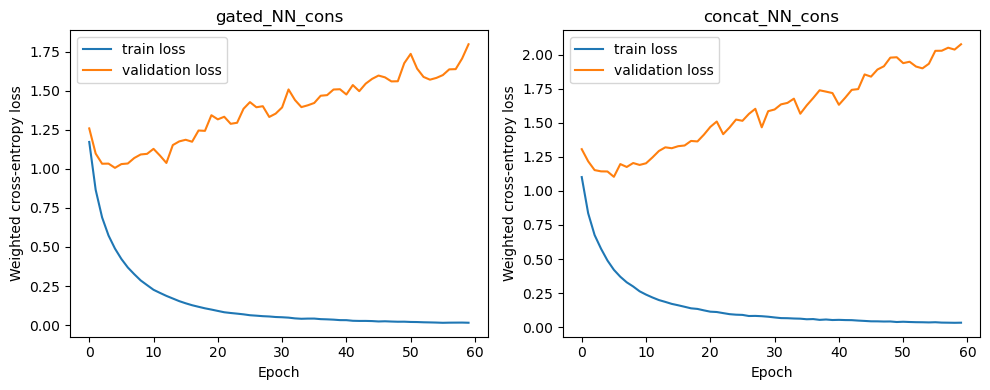

In [ ]:
# Cell 6: gated fusion and concatenation networks
import copy

# gated fusion:the metadata decides how strongly each image feature is used
class GatedFusion(nn.Module):
    def __init__(self,img_dim,meta_dim,hidden=128,p=0.5):
        super().__init__()
        self.img_proj=nn.Sequential(nn.Dropout(p),nn.Linear(img_dim,hidden),nn.ReLU())
        self.gate=nn.Linear(meta_dim,hidden)    # scale for each image feature
        self.bias=nn.Linear(meta_dim,hidden)    # shift for each image feature
        self.out=nn.Sequential(nn.Dropout(p),nn.Linear(hidden,6))
    def forward(self,f,m):
        h=self.img_proj(f)
        h=h*torch.sigmoid(self.gate(m))+torch.tanh(self.bias(m))
        return self.out(h)

# control network: same size, but metadata is just joined to the image features
class ConcatFusion(nn.Module):
    def __init__(self,img_dim,meta_dim,hidden=128,p=0.5):
        super().__init__()
        self.net=nn.Sequential(nn.Dropout(p),nn.Linear(img_dim+meta_dim,hidden),nn.ReLU(),nn.Dropout(p),nn.Linear(hidden, 6))
    def forward(self,f,m):
        return self.net(torch.cat([f,m],dim=1))

# numpy array->float tensor
def T(a):
    return torch.tensor(a,dtype=torch.float32)

# class weights so rare classes count more in the loss
cw=torch.tensor(len(y_train)/(6*np.bincount(y_train)),dtype=torch.float32)

# train for a number of epochs and keep the epoch with the best validation macro-F1
def train_net(net, tr, va, epochs=60):
    f_tr,m_tr,y_tr=tr
    f_va,m_va,y_va=va
    # AdamW optimiser with weight decay
    opt=torch.optim.AdamW(net.parameters(),lr=1e-3,weight_decay=1e-2)
    # cross-entropy loss with class weights
    lossf=nn.CrossEntropyLoss(weight=cw)
    hist=[] #(train loss, val loss, val macro-F1) per epoch
    best_f1=-1
    best_ep=0
    best_state=None
    for ep in range(epochs):
        # training pass over mini-batches of 64
        net.train()
        order=torch.randperm(len(y_tr))
        for i in range(0,len(order),64):
            idx=order[i:i+64]
            opt.zero_grad()
            loss=lossf(net(f_tr[idx],m_tr[idx]),y_tr[idx])
            loss.backward()
            opt.step()
        # evaluation pass: losses and macro-F1 on the validation set
        net.eval()
        with torch.no_grad():
            out_tr=net(f_tr, m_tr)
            out_va=net(f_va, m_va)
            loss_tr=lossf(out_tr, y_tr).item()
            loss_va=lossf(out_va,y_va).item()
        f1_va=f1_score(y_va.numpy(),out_va.argmax(1).numpy(),average="macro")
        hist.append((loss_tr,loss_va,f1_va))
        # remember the best epoch so far
        if f1_va>best_f1:
            best_f1=f1_va
            best_ep=ep + 1
            best_state=copy.deepcopy(net.state_dict())
    net.load_state_dict(best_state) # go back to the best validation epoch
    return hist,best_ep

# train four networks: gated and concat, each with conservative and full metadata
curves={}
for tag in meta_sets:
    M_tr,M_va,M_te=meta_sets[tag]
    for kind,Net in [("gated",GatedFusion),("concat",ConcatFusion)]:
        torch.manual_seed(SEED)
        net=Net(S_tr.shape[1],M_tr.shape[1])
        tr=(T(S_tr),T(M_tr),torch.tensor(y_train))
        va=(T(S_va),T(M_va),torch.tensor(y_val))
        t0=time.time()
        hist,best_ep=train_net(net,tr,va)
        secs=time.time()-t0

        # probabilities for train, val and test
        net.eval()
        p=[]
        with torch.no_grad():
            for S,M in [(S_tr,M_tr),(S_va,M_va),(S_te,M_te)]:
                p.append(torch.softmax(net(T(S),T(M)),1).numpy())

        name=f"{kind}_NN_{tag}"
        probs[name]=tuple(p)
        curves[name]=hist
        print(name," best epoch:",best_ep," train time (s):",round(secs,1))
        evaluate(name,"train",y_train, p[0])
        evaluate(name,"val",y_val, p[1])

res_df=pd.DataFrame(results).round(4)
print(res_df[res_df["model"].str.contains("NN")])

# learning curves (overfitting check), conservative metadata
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,name in zip(axes,["gated_NN_cons","concat_NN_cons"]):
    h=np.array(curves[name])
    ax.plot(h[:,0],label="train loss")
    ax.plot(h[:,1],label="validation loss")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Weighted cross-entropy loss")
    ax.legend()
plt.tight_layout()
plt.savefig(OUT/"fig_learning_curves.png",dpi=200)
plt.show()

In [ ]:
# Cell 7: check that the results are stable across random seeds
# train each network with 5 different seeds to see how much the score moves
stability_rows=[]
for tag in meta_sets:
    M_tr,M_va,M_te=meta_sets[tag]
    for kind,Net in [("gated",GatedFusion),("concat",ConcatFusion)]:
        f1_list=[]
        for s in range(5):
            torch.manual_seed(100+s)
            net=Net(S_tr.shape[1],M_tr.shape[1])
            tr=(T(S_tr),T(M_tr),torch.tensor(y_train))
            va=(T(S_va),T(M_va),torch.tensor(y_val))
            hist,best_ep=train_net(net,tr,va,epochs=50)
            f1_list.append(max(h[2] for h in hist))  # best validation macro-F1
        print(tag,kind,[round(f,3) for f in f1_list])
        stability_rows.append({"metadata":tag,"model":kind,"mean_val_f1":np.mean(f1_list),"std":np.std(f1_list),"min":np.min(f1_list),"max":np.max(f1_list)})

print(pd.DataFrame(stability_rows).round(4))

cons gated [0.674, 0.663, 0.655, 0.665, 0.667]
cons concat [0.61, 0.581, 0.592, 0.59, 0.603]
full gated [0.766, 0.768, 0.772, 0.773, 0.749]
full concat [0.658, 0.649, 0.664, 0.64, 0.657]
  metadata   model  mean_val_f1     std     min     max
0     cons   gated       0.6649  0.0062  0.6549  0.6741
1     cons  concat       0.5952  0.0102  0.5809  0.6101
2     full   gated       0.7656  0.0086  0.7492  0.7731
3     full  concat       0.6536  0.0082  0.6402  0.6639


                       acc  bal_acc  macro_f1  auc_ovr  cancer_sens  \
model                                                                 
late_meta_LR_full   0.7346   0.6926    0.6986   0.9239       0.8387   
concat_NN_full      0.7235   0.6980    0.6951   0.9182       0.8656   
gated_NN_full       0.7374   0.7012    0.6853   0.9391       0.8925   
late_meta_XGB_full  0.7402   0.6812    0.6708   0.9291       0.8656   
early_LR_full       0.6844   0.7102    0.6697   0.9302       0.8710   
early_XGB_full      0.7346   0.6711    0.6694   0.9350       0.9301   
meta_XGB_full       0.7039   0.6643    0.6384   0.9235       0.8978   
gated_NN_cons       0.7011   0.6361    0.6288   0.9122       0.8065   
early_LR_cons       0.6508   0.6205    0.6099   0.8945       0.7957   
concat_NN_cons      0.6453   0.5898    0.5980   0.8886       0.7903   
late_meta_LR_cons   0.6648   0.6112    0.5709   0.8869       0.7849   
late_meta_XGB_cons  0.6536   0.5726    0.5545   0.8871       0.7903   
meta_L

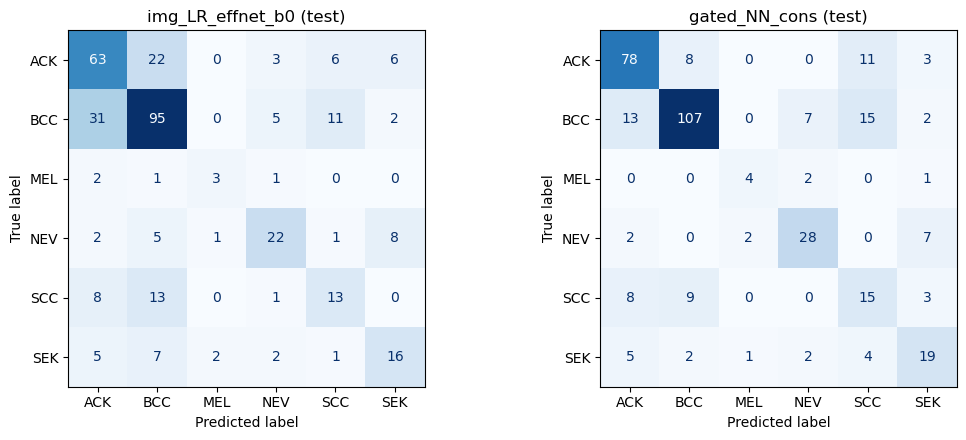

In [ ]:
# Cell 8: final test-set results, bootstrap confidence intervals, recall and confusion matrices
import warnings
warnings.filterwarnings("ignore")
from sklearn.metrics import recall_score,confusion_matrix,ConfusionMatrixDisplay

# 1. every model on the TEST set (first and only time we use it)
for name in probs:
    evaluate(name,"test",y_test, probs[name][2])

res_df=pd.DataFrame(results).round(4)
test_tab=res_df[res_df["split"]=="test"].set_index("model").drop(columns="split")
print(test_tab.sort_values("macro_f1",ascending=False))
res_df.to_csv(OUT/"all_results_train_val_test.csv",index=False)

# 2. patient-level bootstrap: resample patients so one patient's images stay together
main_cons=["img_LR_effnet_b0","meta_LR_cons","late_meta_LR_cons","early_LR_cons","concat_NN_cons","gated_NN_cons"]
main_full=["meta_XGB_full","late_meta_LR_full","early_LR_full","concat_NN_full","gated_NN_full"]
main=main_cons+main_full
# random generator for the bootstrap
rng=np.random.default_rng(SEED)
pat=test_df["patient_id"].values
patient_list=list(np.unique(pat))

# rows that belong to each patient
rows_of_patient={}
for p in patient_list:
    rows_of_patient[p]=np.where(pat==p)[0]

# predicted class for every model on the test set
pred={}
for m in main:
    pred[m]=probs[m][2].argmax(1)

# 1000 bootstrap resamples
B=1000
boot_f1={}
boot_ba={}
for m in main:
    boot_f1[m]=[]
    boot_ba[m]=[]


# each round: resample patients, then recompute the scores
for b in range(B):
    chosen=rng.choice(len(patient_list),len(patient_list),replace=True)
    idx=np.concatenate([rows_of_patient[patient_list[c]] for c in chosen])
    yt=y_test[idx]
    present=np.unique(yt)
    for m in main:
        boot_f1[m].append(f1_score(yt,pred[m][idx],labels=present,average="macro"))
        boot_ba[m].append(balanced_accuracy_score(yt,pred[m][idx]))

# 95% interval = 2.5th to 97.5th percentile of the 1000 scores
ci_rows=[]
for m in main:
    f=np.array(boot_f1[m])
    a=np.array(boot_ba[m])
    ci_rows.append({"model":m,"macro_f1":test_tab.loc[m,"macro_f1"],"f1_lo":np.percentile(f,2.5),"f1_hi":np.percentile(f,97.5),"bal_acc":test_tab.loc[m, "bal_acc"],"ba_lo":np.percentile(a,2.5),"ba_hi":np.percentile(a,97.5)})
ci_tab=pd.DataFrame(ci_rows).round(3)
print(ci_tab)
ci_tab.to_csv(OUT/"test_bootstrap_ci.csv",index=False)

# paired differences in macro-F1 (same bootstrap samples for both models)
pairs=[("gated_NN_cons","img_LR_effnet_b0"),("gated_NN_cons","meta_LR_cons"),("gated_NN_cons","concat_NN_cons"),("early_LR_cons","img_LR_effnet_b0"),("early_LR_cons","late_meta_LR_cons"),("gated_NN_cons","early_LR_cons")]
print("\npaired macro-F1 difference (A - B)")
for a,b_ in pairs:
    d=np.array(boot_f1[a])-np.array(boot_f1[b_])
    print(f"{a} - {b_}: mean {d.mean():.3f}, 95% CI [{np.percentile(d, 2.5):.3f},{np.percentile(d, 97.5):.3f}], "f"share > 0: {(d > 0).mean():.2f}")

# 3. per-class recall on the test set
recall_dict={}
for m in main:
    recall_dict[m]=recall_score(y_test,pred[m],labels=range(6),average=None)
recall_tab=pd.DataFrame(recall_dict,index=classes).T.round(3)
print("\nper-class recall (test)")
print(recall_tab)
recall_tab.to_csv(OUT/"test_per_class_recall.csv")

# 4. confusion matrices: best single-source model vs best fusion model
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
for ax,m in zip(axes,["img_LR_effnet_b0","gated_NN_cons"]):
    cm=confusion_matrix(y_test,pred[m],labels=range(6))
    ConfusionMatrixDisplay(cm,display_labels=classes).plot(ax=ax,colorbar=False,cmap="Blues")
    ax.set_title(m+" (test)")
plt.tight_layout()
plt.savefig(OUT/"fig_confusion_matrices.png",dpi=200)
plt.show()

                 img_id true pred  conf  age region
0  PAT_902_1718_852.png  MEL  NEV  0.87   58  THIGH
1  PAT_115_1138_970.png  MEL  NEV  0.53   70   BACK
2     PAT_45_66_822.png  MEL  SEK  0.86   73  CHEST
3     PAT_53_81_194.png  BCC  ACK  0.98   78   FACE
4   PAT_302_650_477.png  SCC  BCC  0.96   64   FACE
5  PAT_380_1540_432.png  SCC  ACK  0.96   60   NOSE
6     PAT_63_98_127.png  BCC  NEV  0.95   35   FACE
7     PAT_53_81_522.png  BCC  ACK  0.95   78   FACE


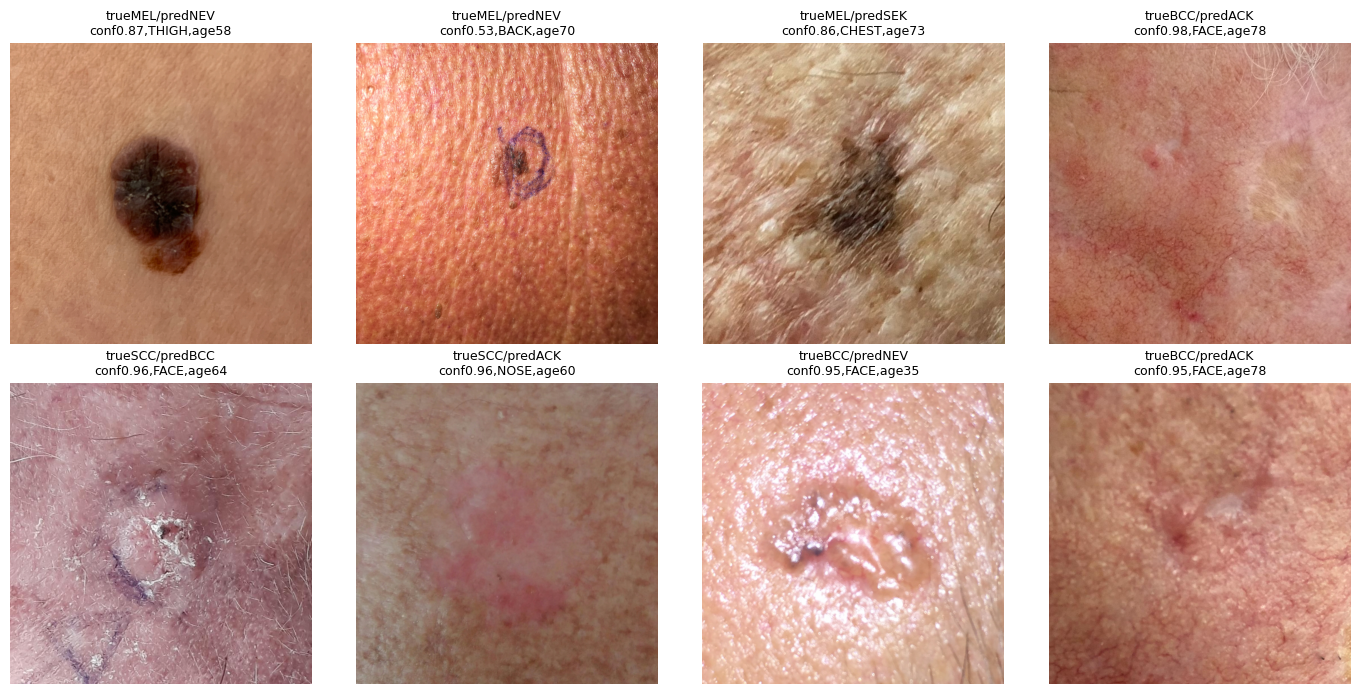


test rows with complete clinical fields: 249  without: 109
diagnoses among test rows WITHOUT clinical fields: {'ACK': 54, 'SEK': 28, 'NEV': 27}
               model      rows    n    acc  macro_f1
0   img_LR_effnet_b0  complete  249  0.562     0.447
1   img_LR_effnet_b0   missing  109  0.661     0.715
2       meta_LR_cons  complete  249  0.558     0.383
3       meta_LR_cons   missing  109  0.606     0.657
4      gated_NN_cons  complete  249  0.663     0.519
5      gated_NN_cons   missing  109  0.789     0.811
6      meta_XGB_full  complete  249  0.675     0.533
7      meta_XGB_full   missing  109  0.771     0.753
8      early_LR_full  complete  249  0.610     0.531
9      early_LR_full   missing  109  0.853     0.840
10     gated_NN_full  complete  249  0.691     0.552
11     gated_NN_full   missing  109  0.844     0.831

Fitzpatrick counts in test: {1.0: 20, 2.0: 161, 3.0: 59, 4.0: 9}
               model            group    n    acc  macro_f1  cancer_sens
0   img_LR_effnet_b0       

In [ ]:
# Cell 9: failure cases, missing-data shortcut check and subgroup results
# A. failure cases for the gated model (conservative metadata) 
p_gated=probs["gated_NN_cons"][2]
pred_gated=p_gated.argmax(1)
conf=p_gated.max(1)

wrong=np.where(pred_gated!=y_test)[0]
mel_wrong=[] # melanoma cases the model got wrong
for i in wrong:
    if y_test[i]==2:
        mel_wrong.append(i)

# other mistakes, most confident first
others=[]
for i in wrong[np.argsort(-conf[wrong])]:
    if y_test[i]!=2:
        others.append(i)

show=(mel_wrong+others)[:8] # all melanoma misses first, then fill up to 8

fail=pd.DataFrame({"img_id":test_df.loc[show,"img_id"].values,"true":[classes[y_test[i]] for i in show],"pred":[classes[pred_gated[i]] for i in show],"conf":conf[show].round(2),"age":test_df.loc[show,"age"].values,"region":test_df.loc[show,"region"].values})
print(fail)

# show the 8 images with true and predicted labels
fig,axes=plt.subplots(2,4,figsize=(14,7))
for ax,i in zip(axes.flatten(),show):
    row=test_df.iloc[i]
    ax.imshow(Image.open(image_paths[row["img_id"]]).convert("RGB"))
    ax.axis("off")
    ax.set_title(f"true{classes[y_test[i]]}/pred{classes[pred_gated[i]]}\n"
                 f"conf{conf[i]:.2f},{row['region']},age{row['age']}",fontsize=9)
plt.tight_layout()
plt.savefig(OUT/"fig_failure_cases.png",dpi=200)
plt.show()

# B. missingness shortcut check 
# gender is empty exactly when the whole clinical block is missing
complete=~(test_df["gender"].isna()|(test_df["gender"].astype(str)=="nan")).values
print("\ntest rows with complete clinical fields:",complete.sum()," without:",(~complete).sum())
print("diagnoses among test rows WITHOUT clinical fields:",test_df.loc[~complete,"diagnostic"].value_counts().to_dict())

# compare models on test rows with and without clinical fields
check_models=["img_LR_effnet_b0","meta_LR_cons","gated_NN_cons","meta_XGB_full","early_LR_full","gated_NN_full"]
shortcut_rows=[]
for m in check_models:
    pm=probs[m][2].argmax(1)
    for group_name,mask in [("complete",complete),("missing",~complete)]:
        yt=y_test[mask]
        shortcut_rows.append({"model": m,"rows":group_name,"n":int(mask.sum()),"acc":(pm[mask]==yt).mean(),"macro_f1":f1_score(yt,pm[mask],labels=np.unique(yt),average="macro")})
print(pd.DataFrame(shortcut_rows).round(3))

# C. subgroup performance 
age=test_df["age"]
# groups by age, sex and skin type
subgroups={"age<50":age<50,"age 50-69":(age >= 50) & (age < 70),"age >= 70":age>=70,"female":test_df["gender"]=="FEMALE","male":test_df["gender"]=="MALE","Fitzpatrick 1-2":test_df["fitspatrick"]<=2,"Fitzpatrick 3-6":test_df["fitspatrick"]>=3}
print("\nFitzpatrick counts in test:",test_df["fitspatrick"].value_counts().sort_index().to_dict())

sub_rows=[]
for m in ["img_LR_effnet_b0","gated_NN_cons"]:
    pm=probs[m][2].argmax(1)
    for group_name,mask in subgroups.items():
        mask=mask.values
        yt=y_test[mask]
        is_cancer=np.isin(yt,cancer)
        pred_cancer=np.isin(pm[mask], cancer)
        if is_cancer.sum()>0:
            sens=pred_cancer[is_cancer].mean()
        else:
            sens=np.nan
        sub_rows.append({"model":m,"group":group_name,"n":int(mask.sum()),"acc":(pm[mask]==yt).mean(),"macro_f1":f1_score(yt,pm[mask],labels=np.unique(yt),average="macro"),"cancer_sens":sens})
sub_tab=pd.DataFrame(sub_rows).round(3)
print(sub_tab)
sub_tab.to_csv(OUT/"test_subgroups.csv",index=False)

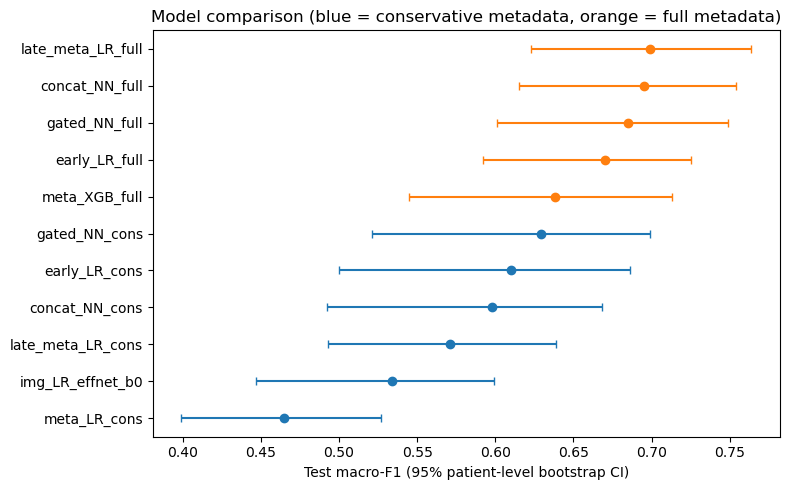

split              train    val   test  train-test gap
model                                                 
img_LR_effnet_b0   0.997  0.501  0.534           0.463
meta_LR_cons       0.531  0.463  0.465           0.066
late_meta_LR_cons  0.799  0.571  0.571           0.228
early_LR_cons      0.823  0.636  0.610           0.213
concat_NN_cons     0.986  0.601  0.598           0.388
gated_NN_cons      0.962  0.680  0.629           0.333
                                                 item         value
0   EfficientNet-B0 embeddings, all 2298 images (CPU)  1.263000e+02
1                                   -> per image (ms)  5.500000e+01
2                               Image-only LR fit (s)  6.300000e-01
3                            Metadata-only LR fit (s)  2.300000e-01
4                      Early fusion fit: PCA + LR (s)  4.600000e-01
5        Gated fusion network training, 50 epochs (s)  1.390000e+01
6              Concat network training, 50 epochs (s)  1.350000e+01
7   Gated head i

In [ ]:
# Cell 10: figure and tables for the report (interval plot, overfitting gap, timing)
# figure: test macro-F1 with 95% bootstrap CI
order=ci_tab.sort_values("macro_f1").reset_index(drop=True)
fig,ax=plt.subplots(figsize=(8,5))
for i,r in order.iterrows():
    if "full" in r["model"]:
        colour="tab:orange"
    else:
        colour="tab:blue"
    ax.errorbar(r["macro_f1"],i,xerr=[[r["macro_f1"]-r["f1_lo"]],[r["f1_hi"]-r["macro_f1"]]],fmt="o",color=colour,capsize=3)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order["model"])
ax.set_xlabel("Test macro-F1 (95% patient-level bootstrap CI)")
ax.set_title("Model comparison (blue = conservative metadata, orange = full metadata)")
plt.tight_layout()
plt.savefig(OUT/"fig_model_comparison_ci.png",dpi=200)
plt.show()

# overfitting table: train vs val vs test macro-F1 
key_models=["img_LR_effnet_b0","meta_LR_cons","late_meta_LR_cons","early_LR_cons","concat_NN_cons","gated_NN_cons"]
gap=res_df.pivot_table(index="model",columns="split",values="macro_f1")[["train","val","test"]]
# a big gap between train and test means overfitting
gap["train-test gap"]=gap["train"]-gap["test"]
print(gap.loc[key_models].round(3))
gap.loc[key_models].round(3).to_csv(OUT/"overfitting_table.csv")

# efficiency: how long each part takes 
# time how long one model fit takes
t0=time.time()
LogisticRegression(C=0.1,max_iter=3000,class_weight="balanced").fit(S_tr, y_train)
t_img=time.time()-t0

t0=time.time()
LogisticRegression(max_iter=2000,class_weight="balanced").fit(Mc_train,y_train)
t_meta=time.time()-t0

t0=time.time()
pca=PCA(n_components=128,random_state=SEED).fit(S_tr)
P=pca.transform(S_tr)
sc_p=StandardScaler().fit(P)
X=np.hstack([sc_p.transform(P),Mc_train])
LogisticRegression(C=0.1,max_iter=3000,class_weight="balanced").fit(X,y_train)
t_early=time.time()-t0

# train both networks again for 50 epochs and time them
nets={}
t_nn={}
for kind,Net in [("gated",GatedFusion),("concat",ConcatFusion)]:
    torch.manual_seed(SEED)
    nets[kind]=Net(S_tr.shape[1],Mc_train.shape[1])
    t0=time.time()
    train_net(nets[kind],(T(S_tr),T(Mc_train),torch.tensor(y_train)),(T(S_va),T(Mc_val),torch.tensor(y_val)),epochs=50)
    t_nn[kind]=time.time()-t0

# inference time of the gated head (without the image backbone)
gated=nets["gated"]
gated.eval()
t0=time.time()
with torch.no_grad():
    for _ in range(20):
        gated(T(S_te),T(Mc_test))
head_ms=(time.time()-t0)/20/len(S_te)*1000

backbone=get_backbone("effnet_b0")
backbone_params=sum(p.numel() for p in backbone.parameters())
ext=extract_time.get("effnet_b0",126.3) # 126.3 s was measured on the first run (embeddings were cached later)

eff=pd.DataFrame([
    ["EfficientNet-B0 embeddings, all 2298 images (CPU)",round(ext,1)],
    ["  -> per image (ms)",round(ext/len(df)*1000,1)],
    ["Image-only LR fit (s)",round(t_img,2)],
    ["Metadata-only LR fit (s)",round(t_meta,2)],
    ["Early fusion fit: PCA + LR (s)",round(t_early,2)],
    ["Gated fusion network training, 50 epochs (s)",round(t_nn["gated"],1)],
    ["Concat network training, 50 epochs (s)",round(t_nn["concat"],1)],
    ["Gated head inference (ms per image, excl. backbone)",round(head_ms,4)],
    ["EfficientNet-B0 backbone parameters",backbone_params],
    ["Gated head parameters",sum(p.numel() for p in nets["gated"].parameters())],
    ["Concat head parameters",sum(p.numel() for p in nets["concat"].parameters())]],
    columns=["item","value"])
print(eff)
eff.to_csv(OUT/"efficiency_table.csv",index=False)

In [ ]:
# Cell 11: 5-fold cross-validation as an extra check on the results
# development set = train + validation together (the test set stays untouched)
dev_df=pd.concat([train_df,val_df]).reset_index(drop=True)
E_dev=np.vstack([emb["effnet_b0"][0],emb["effnet_b0"][1]])   # same row order as dev_df
y_dev=dev_df["label"].values

# train a network for a fixed number of epochs (no validation-based stopping,
# so nothing from the held-out fold leaks into training)
def train_fixed(net,f,m,y,epochs=20):
    w=torch.tensor(len(y)/(6*np.bincount(y,minlength=6)),dtype=torch.float32)
    opt=torch.optim.AdamW(net.parameters(),lr=1e-3,weight_decay=1e-2)
    lossf=nn.CrossEntropyLoss(weight=w)
    for ep in range(epochs):
        net.train()
        order=torch.randperm(len(y))
        for i in range(0,len(order),64):
            idx=order[i:i+64]
            opt.zero_grad()
            loss=lossf(net(f[idx],m[idx]),y[idx])
            loss.backward()
            opt.step()
    return net

# 5 folds, keeping each patient in one fold
cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
model_names=["image_LR","meta_LR_cons","late_fusion","early_fusion","gated_NN"]
cv_f1={}
for n in model_names:
    cv_f1[n]=[]

for fold,(tr,te) in enumerate(cv.split(dev_df,y_dev,groups=dev_df["patient_id"])):
    d_tr=dev_df.iloc[tr]
    d_te=dev_df.iloc[te]
    y_tr=y_dev[tr]
    y_te=y_dev[te]

    # everything below is fitted on this fold's training part only
    prep=make_prep(cons_cat,cons_num)
    M_tr=prep.fit_transform(d_tr)
    M_te=prep.transform(d_te)

    sc=StandardScaler().fit(E_dev[tr])
    Z_tr=sc.transform(E_dev[tr])
    Z_te=sc.transform(E_dev[te])

    fold_probs={}

    # image-only
    lr=LogisticRegression(C=0.1,max_iter=3000,class_weight="balanced").fit(Z_tr, y_tr)
    fold_probs["image_LR"]=lr.predict_proba(Z_te)

    # metadata-only (conservative)
    lr=LogisticRegression(max_iter=2000,class_weight="balanced").fit(M_tr, y_tr)
    fold_probs["meta_LR_cons"]=lr.predict_proba(M_te)

    # late fusion: weight 0.3 on image, 0.7 on metadata (fixed from the validation search)
    fold_probs["late_fusion"]=0.3*fold_probs["image_LR"]+0.7*fold_probs["meta_LR_cons"]

    # early fusion: PCA(128) of the image features + metadata
    pca=PCA(n_components=128,random_state=SEED).fit(Z_tr)
    P_tr=pca.transform(Z_tr)
    P_te=pca.transform(Z_te)
    sc_p=StandardScaler().fit(P_tr)
    X_tr=np.hstack([sc_p.transform(P_tr),M_tr])
    X_te=np.hstack([sc_p.transform(P_te),M_te])
    lr=LogisticRegression(C=0.1,max_iter=3000,class_weight="balanced").fit(X_tr, y_tr)
    fold_probs["early_fusion"]=lr.predict_proba(X_te)

    # gated network, fixed 20 epochs
    torch.manual_seed(SEED+fold)
    net = GatedFusion(Z_tr.shape[1],M_tr.shape[1])
    train_fixed(net,T(Z_tr),T(M_tr),torch.tensor(y_tr),epochs=20)
    net.eval()
    with torch.no_grad():
        fold_probs["gated_NN"]=torch.softmax(net(T(Z_te),T(M_te)),1).numpy()

    # macro-F1 on the held-out fold
    for n in model_names:
        f1=f1_score(y_te,fold_probs[n].argmax(1),labels=np.unique(y_te),average="macro")
        cv_f1[n].append(f1)

    print("fold",fold + 1," test images:",len(te)," patients:",d_te["patient_id"].nunique(),{n:round(cv_f1[n][-1], 3) for n in model_names})

# summary table
cv_summary={"mean_macro_f1":{},"std":{},"folds_beating_image":{}}
for n in model_names:
    scores=np.array(cv_f1[n])
    cv_summary["mean_macro_f1"][n]=scores.mean()
    cv_summary["std"][n]=scores.std()
    cv_summary["folds_beating_image"][n]=int(np.sum(scores>np.array(cv_f1["image_LR"])))

cv_tab=pd.DataFrame(cv_summary)
print(cv_tab.round(3))
cv_tab.round(3).to_csv(OUT/"cv_results.csv")

fold 1  test images: 390  patients: 235 {'image_LR': 0.531, 'meta_LR_cons': 0.462, 'late_fusion': 0.563, 'early_fusion': 0.612, 'gated_NN': 0.606}
fold 2  test images: 372  patients: 235 {'image_LR': 0.549, 'meta_LR_cons': 0.515, 'late_fusion': 0.561, 'early_fusion': 0.592, 'gated_NN': 0.623}
fold 3  test images: 392  patients: 237 {'image_LR': 0.5, 'meta_LR_cons': 0.498, 'late_fusion': 0.587, 'early_fusion': 0.545, 'gated_NN': 0.569}
fold 4  test images: 391  patients: 236 {'image_LR': 0.521, 'meta_LR_cons': 0.46, 'late_fusion': 0.537, 'early_fusion': 0.616, 'gated_NN': 0.62}
fold 5  test images: 395  patients: 233 {'image_LR': 0.533, 'meta_LR_cons': 0.454, 'late_fusion': 0.524, 'early_fusion': 0.577, 'gated_NN': 0.618}
              mean_macro_f1    std  folds_beating_image
image_LR              0.527  0.016                    0
meta_LR_cons          0.478  0.024                    0
late_fusion           0.554  0.022                    4
early_fusion          0.588  0.026           

In [ ]:
# Cell 12: print library versions (for the report appendix and README)
import sys,sklearn,torch,torchvision,xgboost
print("Python",sys.version.split()[0])
print("numpy",np.__version__,"pandas",pd.__version__)
print("scikit-learn",sklearn.__version__)
print("torch",torch.__version__,"torchvision",torchvision.__version__)
print("xgboost",xgboost.__version__)

Python 3.13.5
numpy 2.1.3 pandas 2.2.3
scikit-learn 1.6.1
torch 2.13.0+cpu torchvision 0.28.0+cpu
xgboost 3.4.1
